<a href="https://colab.research.google.com/github/mateosanlu/DeepLearning/blob/main/DL_Laboratorio_Redes_Neuronales_V.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# REDES NEURONALES V
## Red Siamesa, Embeddings y Triplet Loss con PyTorch


**Propósito:** comprender cómo una red aprende una representación vectorial que permite comparar similitud entre ejemplos, y aplicar One-shot y Few-shot Learning de forma controlada y ética.

### Paso 1. Preparar el entorno: importar librerías

En esta etapa inicial importamos todas las dependencias fundamentales para el proyecto. Esto incluye módulos nativos como `math` y `random` para operaciones matemáticas y aleatoriedad, `matplotlib` para la generación de gráficos y visualización de datos, y la biblioteca `PIL` (Pillow) para la manipulación y dibujo sobre imágenes. Finalmente, cargamos el núcleo de `PyTorch` (`torch`, `nn`, `F`) junto con sus utilidades de carga de datos que nos permitirán estructurar el entrenamiento de nuestro modelo de aprendizaje profundo.

In [ ]:
import math
import random
import os
import itertools
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


### Paso 2. Fijar la semilla y seleccionar CPU o GPU

Establecemos una semilla aleatoria fija (`SEED = 42`) en todos los generadores involucrados (Python estándar, NumPy y PyTorch) para garantizar que cada vez que ejecutemos este cuaderno obtengamos exactamente los mismos resultados en la generación de rostros y pesos iniciales de la red. Además, detectamos si el entorno cuenta con soporte de aceleración gráfica (GPU/CUDA) o si operaremos en el procesador central (CPU).

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

print('PyTorch:', torch.__version__)
print('Dispositivo:', DEVICE)


PyTorch: 2.14.1+cpu
Dispositivo: cpu


### Paso 3. Crear una función que genere rostros sintéticos

Definimos un generador procedural de imágenes llamado `synthetic_face`. Esta función dibuja formas geométricas simples (elipses para el rostro y los ojos, líneas para la nariz y arcos para la boca) parametrizadas por la identidad del sujeto. Esto nos permite disponer de un conjunto controlado de imágenes de juguete con variaciones aleatorias de posición y ruido para simular un dataset real sin necesidad de descargar archivos externos de gran tamaño.

In [ ]:
def synthetic_face(identity, variant, size=64):
    rng = random.Random(identity * 1000 + variant)
    img = Image.new('L', (size, size), color=230)
    d = ImageDraw.Draw(img)

    params = [
        (18, 20, 10, 42, 0),
        (16, 22, 12, 40, 1),
        (20, 18, 9, 44, 2),
        (17, 19, 13, 41, 3),
    ][identity]

    eye_dx, eye_y, eye_r, mouth_y, style = params
    jx = rng.randint(-2, 2)
    jy = rng.randint(-2, 2)

    d.ellipse(
        (10+jx, 7+jy, 54+jx, 59+jy),
        fill=185 + identity*10,
        outline=60,
        width=2
    )

    cx = 32 + jx
    ey = eye_y + jy
    for ex in (cx-eye_dx//2, cx+eye_dx//2):
        d.ellipse(
            (ex-eye_r//4, ey-eye_r//4,
             ex+eye_r//4, ey+eye_r//4),
            fill=30
        )

    d.line(
        (cx, ey+4, cx-2, ey+14, cx+2, ey+14),
        fill=70,
        width=2
    )

    if style % 2 == 0:
        d.arc(
            (20+jx, mouth_y-6+jy, 44+jx, mouth_y+8+jy),
            start=10, end=170, fill=40, width=2
        )
    else:
        d.arc(
            (20+jx, mouth_y-2+jy, 44+jx, mouth_y+12+jy),
            start=190, end=350, fill=40, width=2
        )

    if style == 1:
        d.line((18+jx, 15+jy, 46+jx, 15+jy),
               fill=40, width=3)
    if style == 2:
        d.ellipse((24+jx, 44+jy, 40+jx, 49+jy),
                  outline=40, width=2)
    if style == 3:
        d.line((15+jx, 28+jy, 49+jx, 28+jy),
               fill=90, width=1)

    arr = np.array(img, dtype=np.float32)
    noise = np.random.default_rng(
        identity*100 + variant
    ).normal(0, 3, arr.shape)
    arr = np.clip(arr + noise, 0, 255).astype(np.uint8)
    return arr

### Paso 4. Construir el dataset pedagógico

Con la función generadora lista, creamos nuestro conjunto de datos de entrenamiento iterando sobre 4 identidades distintas y generando 12 variaciones sutiles para cada una. Al final, apilamos los arreglos en un tensor de NumPy para tener una estructura multidimensional que representa nuestro lote de imágenes listo para ser convertido al formato compatible de PyTorch.

In [ ]:
N_ID = 4
N_PER = 12
images = []
labels = []

for ident in range(N_ID):
    for variant in range(N_PER):
        images.append(synthetic_face(ident, variant))
        labels.append(ident)

images = np.stack(images)
labels = np.array(labels)

print('Forma:', images.shape)
print('Etiquetas:', labels.shape)
print('Rango:', images.min(), images.max())


Forma: (48, 64, 64)
Etiquetas: (48,)
Rango: 20 241


### Paso 5. Visualizar ejemplos del dataset

Antes de alimentar la red neuronal, es crucial comprobar visualmente la calidad de nuestros datos de juguete. Creamos una cuadrícula usando Matplotlib para mostrar las primeras 5 variaciones de cada una de las 4 identidades. Así podemos verificar cómo el generador añade ruido y pequeños desplazamientos espaciales manteniendo los rasgos distintivos que caracterizan a cada rostro.

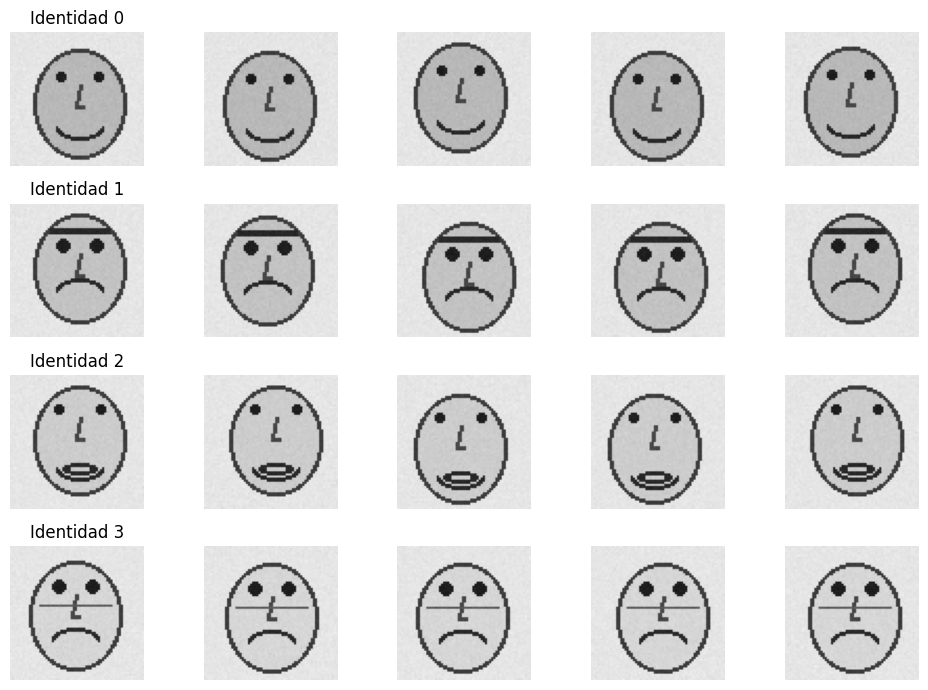

In [ ]:
fig, axes = plt.subplots(N_ID, 5, figsize=(10, 7))

for i in range(N_ID):
    idx = np.where(labels == i)[0][:5]

    for j, k in enumerate(idx):
        axes[i, j].imshow(
            images[k],
            cmap='gray',
            vmin=0,
            vmax=255
        )
        axes[i, j].axis('off')

        if j == 0:
            axes[i, j].set_title(f'Identidad {i}')

plt.tight_layout()
plt.show()


### Paso 6. Convertir las imágenes a tensores de PyTorch

Las redes neuronales en PyTorch requieren tensores de punto flotante con una estructura de canales específica (generalmente `[Lote, Canales, Alto, Ancho]`). Aquí convertimos nuestras imágenes NumPy a tensores, agregamos la dimensión del canal monocromo mediante `unsqueeze(1)` y normalizamos los valores de píxel dividiendo por 255.0 para dejarlos en un rango óptimo de 0 a 1.

In [ ]:
X = torch.tensor(images, dtype=torch.float32)
X = X.unsqueeze(1) / 255.0

y = torch.tensor(labels, dtype=torch.long)

print('X:', X.shape)
print('y:', y.shape)
print('Rango X:', float(X.min()), float(X.max()))


X: torch.Size([48, 1, 64, 64])
y: torch.Size([48])
Rango X: 0.0784313753247261 0.9450980424880981


### Paso 7. Crear el Dataset de tripletas Anchor–Positive–Negative

Implementamos una clase personalizada heredando de `Dataset` de PyTorch. En lugar de devolver pares individuales de imagen-etiqueta, este cargador selecciona para cada muestra un ancla ('Anchor'), una imagen diferente de su misma clase ('Positive') y una imagen perteneciente a una clase totalmente distinta ('Negative'). Este triplete es la estructura indispensable requerida por la función de pérdida Triplet Loss.

In [ ]:
class TripletFaces(Dataset):
    def __init__(self, X, y, triplets_per_epoch=400):
        self.X = X
        self.y = y
        self.n = triplets_per_epoch

        self.by_class = {
            int(c): torch.where(y == c)[0].tolist()
            for c in torch.unique(y)
        }
        self.classes = list(self.by_class)

    def __len__(self):
        return self.n

    def __getitem__(self, idx):
        a_class = random.choice(self.classes)

        other_classes = [
            c for c in self.classes
            if c != a_class
        ]
        n_class = random.choice(other_classes)

        a_idx, p_idx = random.sample(
            self.by_class[a_class], 2
        )
        n_idx = random.choice(
            self.by_class[n_class]
        )

        return (
            self.X[a_idx],
            self.X[p_idx],
            self.X[n_idx],
            a_class,
            n_class
        )


### Paso 8. Crear y observar una tripleta

Instanciamos nuestra clase de datos de tripletas y graficamos un ejemplo de salida. Visualizamos de forma paralela el Anchor, el Positive y el Negative. Esto nos sirve para constatar visualmente que el cargador asocia adecuadamente dos variaciones de la misma persona y un rostro perteneciente a una identidad diferente.

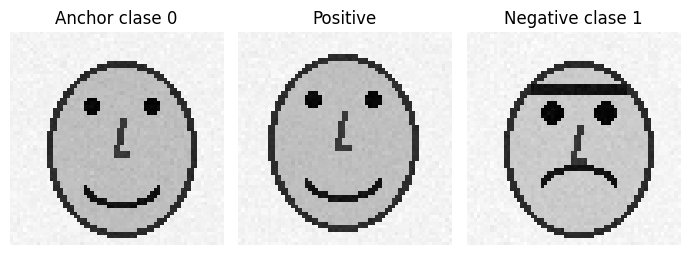

In [ ]:
trip = TripletFaces(X, y, triplets_per_epoch=400)

a, p, n, ca, cn = trip[0]

fig, ax = plt.subplots(1, 3, figsize=(7, 2.5))

for tensor_img, title, axis in [
    (a, f'Anchor clase {ca}', ax[0]),
    (p, 'Positive', ax[1]),
    (n, f'Negative clase {cn}', ax[2])
]:
    axis.imshow(tensor_img.squeeze(), cmap='gray')
    axis.set_title(title)
    axis.axis('off')

plt.tight_layout()
plt.show()


### Paso 9. Construir el encoder de embeddings

Diseñamos la arquitectura de nuestra red neuronal convolucional (CNN). El propósito de este 'Encoder' es mapear la imagen de entrada en un espacio vectorial de dimensión reducida (64 elementos). La red consta de capas de convolución, activación ReLU, submuestreo MaxPool y una capa lineal final cuyos vectores de salida son normalizados a longitud unitaria ($L_2$) para facilitar la comparación de distancias.

In [ ]:
class Encoder(nn.Module):
    def __init__(self, emb_dim=64):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(8, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.fc = nn.Linear(32 * 4 * 4, emb_dim)

    def forward(self, x):
        z = self.features(x)
        z = z.flatten(1)
        z = self.fc(z)
        z = F.normalize(z, p=2, dim=1)
        return z


### Paso 10. Instanciar el encoder y probar un embedding

Inicializamos el modelo en el dispositivo seleccionado (CPU o GPU) y realizamos una propagación hacia adelante ('forward pass') de prueba utilizando dos imágenes de nuestro dataset. Esto nos permite comprobar que el modelo compila correctamente y entrega vectores de características de la dimensión esperada (64 valores por imagen) sin generar errores de arquitectura.

In [ ]:
model = Encoder(emb_dim=64).to(DEVICE)

print(model)

with torch.no_grad():
    example_embedding = model(
        X[:2].to(DEVICE)
    )

print(
    'Embedding de ejemplo:',
    example_embedding.shape
)


Encoder(
  (features): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (fc): Linear(in_features=512, out_features=64, bias=True)
)
Embedding de ejemplo: torch.Size([2, 64])


### Paso 11. Preparar DataLoader, Triplet Loss y optimizador

Configuramos el flujo final del entrenamiento. Definimos un `DataLoader` para agrupar las tripletas en lotes aleatorios de tamaño 32. Establecemos `TripletMarginLoss` como nuestra función de pérdida con un margen de seguridad de 0.8, y seleccionamos el optimizador Adam con una tasa de aprendizaje de 1e-3 para ajustar los pesos del modelo basándose en los gradientes calculados.

In [ ]:
loader = DataLoader(
    trip,
    batch_size=32,
    shuffle=True
)

criterion = nn.TripletMarginLoss(
    margin=0.8,
    p=2
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

### Paso 12. Entrenar el modelo con Triplet Loss

Ejecutamos el ciclo principal de entrenamiento durante varias épocas. Para cada lote, pasamos las imágenes Anchor, Positive y Negative por el encoder, calculamos la pérdida de triplete (que penaliza si el Anchor está más cerca del Negative que del Positive más el margen) y actualizamos los parámetros del modelo mediante retropropagación.

In [ ]:
losses = []

for epoch in range(18):
    model.train()
    total = 0
    count = 0

    for a, p, n, _, _ in loader:
        a = a.to(DEVICE)
        p = p.to(DEVICE)
        n = n.to(DEVICE)

        za = model(a)
        zp = model(p)
        zn = model(n)

        loss = criterion(za, zp, zn)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total += loss.item() * a.size(0)
        count += a.size(0)

    mean_loss = total / count
    losses.append(mean_loss)

    if epoch in [0, 1, 2, 5, 10, 17]:
        print(
            f'Época {epoch+1:02d} | '
            f'loss={mean_loss:.4f}'
        )


Época 01 | loss=0.3981
Época 02 | loss=0.0266
Época 03 | loss=0.0024
Época 06 | loss=0.0000
Época 11 | loss=0.0002
Época 18 | loss=0.0000


### Paso 13. Graficar la evolución de Triplet Loss

Dibujamos la curva de la función de pérdida a lo largo de las épocas de entrenamiento utilizando Matplotlib. El descenso continuo y asintótico de la curva hacia cero confirma que la red está aprendiendo con éxito a proyectar las imágenes en un espacio de embeddings donde se respeta la similitud semántica de las identidades.

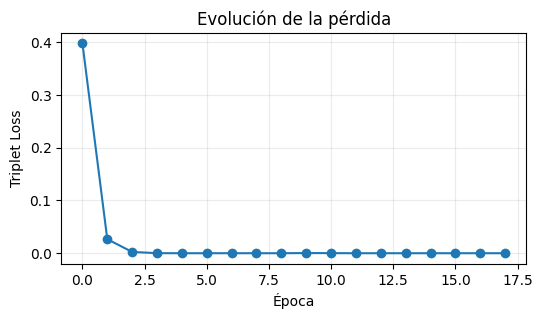

In [ ]:
plt.figure(figsize=(6, 3))
plt.plot(losses, marker='o')
plt.xlabel('Época')
plt.ylabel('Triplet Loss')
plt.title('Evolución de la pérdida')
plt.grid(alpha=.25)
plt.show()

### Paso 14. Extraer embeddings de todas las imágenes

Ponemos el modelo entrenado en modo de evaluación (`eval`) para desactivar cualquier comportamiento propio del entrenamiento y extraemos los vectores de características (embeddings) para el total de las 48 imágenes de nuestro conjunto de datos. Almacenamos estas proyecciones en una matriz `Z` que utilizaremos para las pruebas cuantitativas.

In [ ]:
model.eval()

with torch.no_grad():
    Z = model(
        X.to(DEVICE)
    ).cpu()

print('Forma de Z:', Z.shape)


Forma de Z: torch.Size([48, 64])


### Paso 15. Comparar distancias positivas y negativas

Calculamos las distancias euclidianas entre todos los pares posibles de embeddings en nuestro dataset. Clasificamos las distancias en dos grupos: pares de la misma identidad (positivos) y pares de identidades distintas (negativos). Graficamos ambos grupos en un histograma para evaluar el nivel de separación y superposición de las distribuciones.

Distancia positiva media: 0.1312
Distancia negativa media: 1.5421


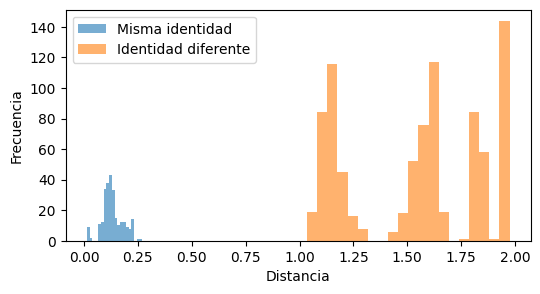

In [ ]:
pos = []
neg = []

for i in range(len(X)):
    for j in range(i + 1, len(X)):
        distance = torch.dist(
            Z[i], Z[j]
        ).item()

        if labels[i] == labels[j]:
            pos.append(distance)
        else:
            neg.append(distance)

print(
    'Distancia positiva media:',
    round(float(np.mean(pos)), 4)
)
print(
    'Distancia negativa media:',
    round(float(np.mean(neg)), 4)
)

plt.figure(figsize=(6, 3))
plt.hist(
    pos, bins=20, alpha=.6,
    label='Misma identidad'
)
plt.hist(
    neg, bins=20, alpha=.6,
    label='Identidad diferente'
)
plt.legend()
plt.xlabel('Distancia')
plt.ylabel('Frecuencia')
plt.show()


### Paso 16. Implementar One-shot Learning

Evaluamos la capacidad del sistema para reconocer una cara con solo ver un ejemplo de referencia. Tomamos la primera imagen de cada una de las 4 clases como galería de referencia y clasificamos las imágenes restantes comparándolas con esta galería. Medimos el rendimiento global calculando el porcentaje de aciertos (accuracy) obtenido.

In [ ]:
refs = {
    c: np.where(labels == c)[0][0]
    for c in range(N_ID)
}

queries = [
    i for i in range(len(X))
    if i not in refs.values()
]

correct = 0

for i in queries:
    dists = {
        c: torch.dist(
            Z[i], Z[idx]
        ).item()
        for c, idx in refs.items()
    }

    pred = min(dists, key=dists.get)
    correct += int(pred == labels[i])

acc_one = correct / len(queries)

print(
    'Accuracy One-shot:',
    round(acc_one, 4),
    f'({correct}/{len(queries)})'
)


Accuracy One-shot: 1.0 (44/44)


### Paso 17. Implementar Few-shot Learning

Para robustecer la clasificación, incrementamos el número de imágenes de referencia por identidad en la galería. En lugar de una sola imagen, promediamos los embeddings de las primeras muestras de cada clase para crear un vector 'prototipo' representativo. Clasificamos las imágenes restantes contra estos prototipos estables y comparamos el resultado con el desempeño de One-shot.

In [ ]:
ref_ids = {
    c: np.where(labels == c)[0][:3]
    for c in range(N_ID)
}

prototypes = {}

for c, idx in ref_ids.items():
    proto = Z[idx].mean(
        0, keepdim=True
    )
    proto = F.normalize(
        proto, p=2, dim=1
    )
    prototypes[c] = proto.squeeze(0)

query_ids = [
    i for i in range(len(X))
    if all(
        i not in ids
        for ids in ref_ids.values()
    )
]

correct = 0

for i in query_ids:
    dists = {
        c: torch.dist(
            Z[i], proto
        ).item()
        for c, proto in prototypes.items()
    }

    pred = min(dists, key=dists.get)
    correct += int(pred == labels[i])

acc_few = correct / len(query_ids)

print(
    'Accuracy Few-shot:',
    round(acc_few, 4),
    f'({correct}/{len(query_ids)})'
)
print(
    'Comparación -> One-shot:',
    round(acc_one, 4),
    '| Few-shot:',
    round(acc_few, 4)
)


Accuracy Few-shot: 1.0 (36/36)
Comparación -> One-shot: 1.0 | Few-shot: 1.0


### Paso 18. Definir un umbral pedagógico de verificación

Establecemos un umbral intermedio entre las distancias de pares positivos y negativos. Este límite nos ayuda a tomar decisiones de verificación binaria: si dos rostros están a una distancia menor al umbral se consideran la misma persona, de lo contrario se declaran diferentes. Probamos esta lógica con un par concordante y un par discordante.

In [ ]:
threshold = (
    float(np.mean(pos)) +
    float(np.mean(neg))
) / 2

print(
    'Umbral pedagógico:',
    round(threshold, 4)
)

def verify(i, j):
    distance = torch.dist(
        Z[i], Z[j]
    ).item()

    same_identity = distance < threshold
    return distance, same_identity

same = np.where(labels == 0)[0][:2]

diff = (
    np.where(labels == 0)[0][0],
    np.where(labels == 1)[0][0]
)

for pair in [tuple(same), diff]:
    distance, ok = verify(*pair)
    result = 'MISMA' if ok else 'DIFERENTE'

    print(
        pair,
        'dist=', round(distance, 4),
        '=>', result
    )


Umbral pedagógico: 0.8367
(np.int64(0), np.int64(1)) dist= 0.207 => MISMA
(np.int64(0), np.int64(12)) dist= 1.2789 => DIFERENTE


### Paso 19. Comprender por qué este experimento no demuestra Zero-shot real

Analizamos conceptualmente el alcance de nuestra validación actual. Explicamos que, dado que el modelo se entrenó con variantes de las mismas identidades que usamos para evaluar el reconocimiento, no estamos ante un escenario de generalización a clases totalmente desconocidas (Zero-shot), lo cual requeriría evaluar la red con personas que jamás se usaron en el proceso de optimización.

In [ ]:
# No se requiere código nuevo en este paso.
# El modelo fue entrenado con las mismas cuatro identidades
# sintéticas usadas posteriormente en las pruebas.
# Por tanto, esta práctica NO demuestra zero-shot facial real.


### Paso 20. Preparar la carga de fotografías propias o autorizadas

Definimos una función utilitaria en Python para automatizar la lectura de un directorio local de imágenes reales. Esta función se encarga de recorrer las carpetas de las identidades, cargar los archivos en escala de grises, redimensionarlos a 64x64 píxeles y transformarlos en tensores listos para que nuestro encoder pueda procesarlos de manera uniforme.

In [ ]:
from pathlib import Path

def load_authorized_faces(
    root='/content/rostros',
    size=(64, 64)
):
    root = Path(root)
    imgs = []
    labs = []
    names = []

    if not root.exists():
        print('Aún no existe', root)
        return None, None, None

    persons = sorted([
        p for p in root.iterdir()
        if p.is_dir()
    ])

    for label, person in enumerate(persons):
        names.append(person.name)

        for fp in sorted(person.glob('*')):
            if fp.suffix.lower() not in {
                '.jpg', '.jpeg', '.png', '.webp'
            }:
                continue

            img = Image.open(fp)
            img = img.convert('L').resize(size)

            imgs.append(
                np.array(img, dtype=np.uint8)
            )
            labs.append(label)

    if not imgs:
        print('No se encontraron imágenes.')
        return None, None, names

    Xr = torch.tensor(
        np.stack(imgs),
        dtype=torch.float32
    ).unsqueeze(1) / 255.0

    yr = torch.tensor(
        labs,
        dtype=torch.long
    )

    print('Personas:', names)
    print('Xr:', Xr.shape, 'yr:', yr.shape)

    return Xr, yr, names


### Paso 21. Organizar las carpetas y cargar imágenes autorizadas

Mostramos y probamos el flujo de inicialización con la función de carga de retratos reales. Se busca comprobar si la estructura de carpetas local contiene imágenes compatibles y se ejecuta la transformación a tensores de PyTorch para verificar que las dimensiones finales se acoplen con el pipeline convolucional previamente entrenado.

In [ ]:
# Estructura sugerida:
# /content/rostros/
#   persona_01/
#       foto1.jpg
#       foto2.jpg
#       foto3.jpg
#   persona_02/
#       foto1.jpg
#       foto2.jpg
#       foto3.jpg

Xr, yr, names = load_authorized_faces(
    '/content/rostros'
)


Personas: ['.ipynb_checkpoints', 'persona_01', 'persona_02']
Xr: torch.Size([6, 1, 64, 64]) yr: torch.Size([6])


# PRACTICA COMPLEMENTARIA CON FOTOGRAFÍAS REALES
## Embeddings · Triplet Learning · Similitud · Few-shot Learning

**Propósito:** Aplicar el modelo de embeddings desarrollado anteriormente a fotografías reales para analizar la robustez y comportamiento de similitud en un entorno real.

### Punto de partida
Esta guía continúa la práctica de Redes Neuronales V. Se asume que el modelo `model` (FaceEncoder) ya está instanciado y entrenado.

Trabajaremos con seis fotografías en total: tres imágenes de Persona 1 y tres imágenes de Persona 2. El flujo será: cargar → organizar → preprocesar → convertir a tensor → generar embeddings → evaluar distancias euclidianas.

### Paso 1. Comprobar que el modelo de la práctica anterior sigue disponible

Verificamos que el modelo previamente entrenado (`model`) y el dispositivo configurado (`DEVICE`) sigan cargados en el estado de ejecución actual del kernel de Jupyter para asegurar la continuidad del pipeline con las fotografías reales sin necesidad de volver a compilar y entrenar la red convolucional desde cero.

In [ ]:
print('Modelo disponible:', 'model' in globals())
print('DEVICE disponible:', 'DEVICE' in globals())

if 'model' not in globals() or 'DEVICE' not in globals():
    print('Debes ejecutar primero la práctica principal de Redes Neuronales V.')
else:
    print('Podemos continuar con fotografías reales.')


Modelo disponible: True
DEVICE disponible: True
Podemos continuar con fotografías reales.


### Paso 2. Importar las librerías necesarias para fotografías reales

Cargamos las librerías y utilidades auxiliares específicas para esta sección del experimento. Esto incluye módulos para la manipulación y organización del sistema de archivos (`os`, `shutil`, `pathlib`), visualización de gráficos (`matplotlib`), procesamiento y acondicionamiento de imágenes reales (`PIL.Image`, `PIL.ImageOps`), y el módulo de subida de archivos de Google Colab (`google.colab.files`) para interactuar de forma interactiva con el almacenamiento local.

In [ ]:
import os
import shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from PIL import Image, ImageOps

import torch
import torch.nn.functional as F

from google.colab import files

print('Librerías cargadas correctamente')


Librerías cargadas correctamente


### Paso 3. Crear una carpeta limpia para el experimento

Preparamos el directorio de trabajo eliminando cualquier rastro de archivos de ejecuciones previas dentro de la ruta `/content/rostros`. Posteriormente, creamos de forma limpia las subcarpetas de destino para alojar por separado los retratos de las dos personas que utilizaremos en la validación real.

In [ ]:
ruta_base = '/content/rostros'

if os.path.exists(ruta_base):
    shutil.rmtree(ruta_base)

os.makedirs('/content/rostros/persona_01', exist_ok=True)
os.makedirs('/content/rostros/persona_02', exist_ok=True)

print('Carpetas preparadas:')
print('/content/rostros/persona_01')
print('/content/rostros/persona_02')


Carpetas preparadas:
/content/rostros/persona_01
/content/rostros/persona_02


### Paso 4. Cargar tres fotografías de Persona 1

Invocamos el widget de carga interactiva de archivos para que el usuario pueda seleccionar y subir exactamente 3 imágenes correspondientes a la primera identidad (Persona 1). El bloque guarda estos archivos directamente en su directorio específico de forma automatizada.

In [ ]:
print('Seleccione EXACTAMENTE 3 fotografías de PERSONA 1')

fotos_persona1 = files.upload()

if len(fotos_persona1) != 3:
    print('ADVERTENCIA: se esperaban 3 archivos y se cargaron', len(fotos_persona1))

for nombre, contenido in fotos_persona1.items():
    ruta = '/content/rostros/persona_01/' + nombre
    with open(ruta, 'wb') as archivo:
        archivo.write(contenido)

print('Fotos de Persona 1 guardadas:', len(fotos_persona1))


Seleccione EXACTAMENTE 3 fotografías de PERSONA 1


Saving NPfoto3 (1).jpg to NPfoto3 (1) (1).jpg
Saving NPfoto3 (2).jpg to NPfoto3 (2).jpg
Saving NPfoto3 (3).jpg to NPfoto3 (3).jpg
Fotos de Persona 1 guardadas: 3


### Paso 5. Cargar tres fotografías de Persona 2

Repetimos el proceso de carga de archivos de forma interactiva, esta vez seleccionando y resguardando en el disco de Colab las 3 imágenes correspondientes a la segunda identidad (Persona 2) para completar nuestra base de datos real.

In [ ]:
print('Seleccione EXACTAMENTE 3 fotografías de PERSONA 2')

fotos_persona2 = files.upload()

if len(fotos_persona2) != 3:
    print('ADVERTENCIA: se esperaban 3 archivos y se cargaron', len(fotos_persona2))

for nombre, contenido in fotos_persona2.items():
    ruta = '/content/rostros/persona_02/' + nombre
    with open(ruta, 'wb') as archivo:
        archivo.write(contenido)

print('Fotos de Persona 2 guardadas:', len(fotos_persona2))


Seleccione EXACTAMENTE 3 fotografías de PERSONA 2


Saving foto3.jpg to foto3.jpg
Saving foto2.jpg to foto2.jpg
Saving foto1.jpg to foto1.jpg
Fotos de Persona 2 guardadas: 3


### Paso 6. Verificar la estructura de las carpetas

Realizamos una inspección del sistema de archivos recorriendo recursivamente el directorio `/content/rostros`. Esto nos permite imprimir en pantalla la ubicación exacta de cada fotografía guardada y validar que la distribución jerárquica de carpetas sea correcta antes de pasar a la fase de preprocesamiento.

In [ ]:
total = 0

for carpeta, subcarpetas, archivos in os.walk('/content/rostros'):
    print('\nCarpeta:', carpeta)
    for archivo in archivos:
        print('   ', archivo)
        total += 1

print('\nTotal de archivos encontrados:', total)


Carpeta: /content/rostros

Carpeta: /content/rostros/persona_02
    foto3.jpg
    foto2.jpg
    foto1.jpg

Carpeta: /content/rostros/persona_01
    foto3.jpg
    foto2.jpg
    foto1.jpg

Carpeta: /content/rostros/persona_01/.ipynb_checkpoints

Total de archivos encontrados: 6


### Paso 7. Visualizar las seis fotografías originales

Cargamos y mostramos de forma paralela en una cuadrícula las seis imágenes cargadas en su formato RGB original. Esta visualización previa nos sirve para certificar la nitidez de las capturas y confirmar que la segmentación de identidades corresponde con las carpetas asignadas.

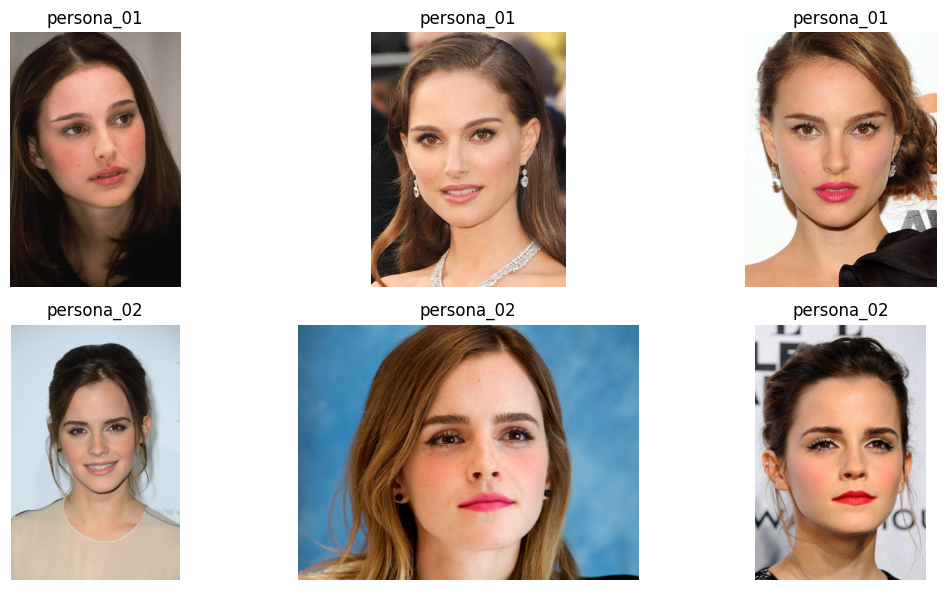

In [ ]:
carpetas = [
    '/content/rostros/persona_01',
    '/content/rostros/persona_02'
]

plt.figure(figsize=(12, 6))
posicion = 1

for carpeta in carpetas:
    persona = os.path.basename(carpeta)

    for archivo in sorted(os.listdir(carpeta)):
        if archivo.lower().endswith(('.jpg', '.jpeg', '.png', '.webp')):
            ruta = os.path.join(carpeta, archivo)
            imagen = Image.open(ruta).convert('RGB')

            plt.subplot(2, 3, posicion)
            plt.imshow(imagen)
            plt.title(persona)
            plt.axis('off')

            posicion += 1

plt.tight_layout()
plt.show()

### Paso 8. Crear la función de preprocesamiento

Definimos la lógica especializada para homogeneizar las dimensiones y formato de nuestras fotografías reales. La función `cargar_rostros` lee las imágenes, las pasa a escala de grises, realiza un recorte proporcional ajustado ('fit') al tamaño de entrada del encoder (64x64 píxeles) y empaqueta el lote en tensores normalizados de PyTorch.

In [ ]:
def cargar_rostros(carpeta='/content/rostros', tamano=(64, 64)):
    carpeta = Path(carpeta)

    imagenes = []
    etiquetas = []
    nombres_personas = []

    personas = sorted([p for p in carpeta.iterdir() if p.is_dir()])

    for etiqueta, persona in enumerate(personas):
        nombres_personas.append(persona.name)
        print('Leyendo:', persona.name)

        for archivo in sorted(persona.glob('*')):
            if archivo.suffix.lower() not in {'.jpg', '.jpeg', '.png', '.webp'}:
                continue

            imagen = Image.open(archivo).convert('L')
            imagen = ImageOps.fit(imagen, tamano)
            imagen = np.array(imagen, dtype=np.uint8)

            imagenes.append(imagen)
            etiquetas.append(etiqueta)

    Xr = torch.tensor(np.stack(imagenes), dtype=torch.float32)
    Xr = Xr.unsqueeze(1) / 255.0

    yr = torch.tensor(etiquetas, dtype=torch.long)

    return Xr, yr, nombres_personas


### Paso 9. Convertir las seis fotografías a tensores

Ejecutamos la función de preprocesamiento sobre el directorio que contiene las fotos reales. Verificamos que se detecten ambas personas y validamos las dimensiones y tipos de datos de los tensores resultantes (`Xr` para las imágenes y `yr` para sus etiquetas respectivas de clase).

In [ ]:
Xr, yr, nombres = cargar_rostros('/content/rostros')

print('Personas encontradas:', nombres)
print('Forma de las imágenes:', Xr.shape)
print('Etiquetas:', yr)


Leyendo: persona_01
Leyendo: persona_02
Personas encontradas: ['persona_01', 'persona_02']
Forma de las imágenes: torch.Size([6, 1, 64, 64])
Etiquetas: tensor([0, 0, 0, 1, 1, 1])


### Paso 10. Visualizar las fotografías ya procesadas

Graficamos las seis fotografías convertidas a escala de grises y redimensionadas a 64x64 píxeles. Esta inspección visual nos permite constatar el resultado de las transformaciones de preprocesamiento y cómo serán percibidos estos rostros reales por la red neuronal.

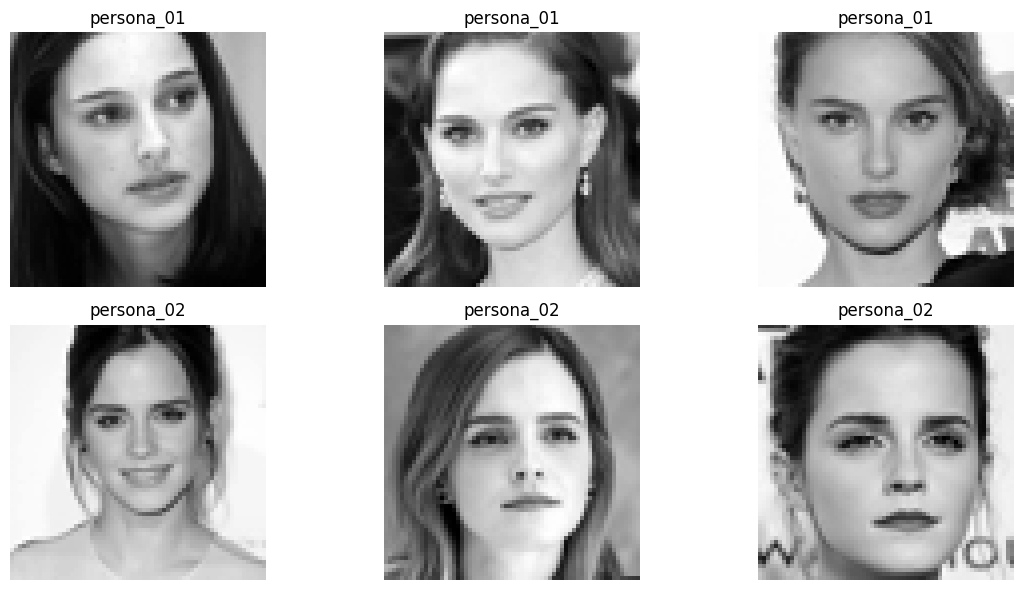

In [ ]:
plt.figure(figsize=(12, 6))

for i in range(len(Xr)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(Xr[i].squeeze(), cmap='gray')
    plt.title(nombres[yr[i].item()])
    plt.axis('off')

plt.tight_layout()
plt.show()


### Paso 11. Seleccionar Anchor, Positive y Negative

Establecemos un subconjunto de prueba extrayendo manualmente imágenes de nuestros tensores reales. Designamos una imagen de la Persona 1 como ancla ('Anchor'), otra foto de la misma Persona 1 como el caso positivo ('Positive') y una foto de la Persona 2 como el caso negativo ('Negative').

In [ ]:
anchor = Xr[0]       # Persona 1
positive = Xr[1]     # Persona 1
negative = Xr[3]     # Persona 2

print('Anchor:', anchor.shape)
print('Positive:', positive.shape)
print('Negative:', negative.shape)


Anchor: torch.Size([1, 64, 64])
Positive: torch.Size([1, 64, 64])
Negative: torch.Size([1, 64, 64])


### Paso 12. Visualizar el triple real

Graficamos de forma conjunta el trío de imágenes reales seleccionado en el paso anterior. Esto proporciona una confirmación visual clara de la relación del triplete bajo prueba: los dos primeros pertenecen a la misma identidad mientras que el tercero sirve de contraejemplo.

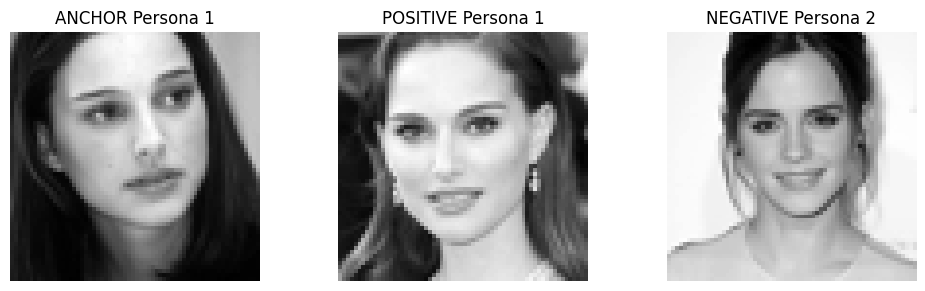

In [ ]:
plt.figure(figsize=(10, 3))

plt.subplot(1, 3, 1)
plt.imshow(anchor.squeeze(), cmap='gray')
plt.title('ANCHOR Persona 1')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(positive.squeeze(), cmap='gray')
plt.title('POSITIVE Persona 1')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(negative.squeeze(), cmap='gray')
plt.title('NEGATIVE Persona 2')
plt.axis('off')

plt.tight_layout()
plt.show()


### Paso 13. Generar los tres embeddings

Pasamos nuestras tres imágenes reales de prueba (con una dimensión de lote agregada) a través del encoder para extraer sus vectores representativos en el espacio latente. Esto nos da un vector compacto de tamaño 64 para cada uno de los elementos de la prueba.

In [ ]:
model.eval()

with torch.no_grad():
    anchor_batch = anchor.unsqueeze(0).to(DEVICE)
    positive_batch = positive.unsqueeze(0).to(DEVICE)
    negative_batch = negative.unsqueeze(0).to(DEVICE)

    embedding_anchor = model(anchor_batch)
    embedding_positive = model(positive_batch)
    embedding_negative = model(negative_batch)

print('Embedding Anchor:', embedding_anchor.shape)
print('Embedding Positive:', embedding_positive.shape)
print('Embedding Negative:', embedding_negative.shape)


Embedding Anchor: torch.Size([1, 64])
Embedding Positive: torch.Size([1, 64])
Embedding Negative: torch.Size([1, 64])


### Paso 14. Observar algunos valores de los embeddings

Imprimimos en pantalla los primeros 10 elementos de cada uno de los embeddings generados para el Anchor, Positive y Negative. Esto nos permite observar directamente los valores de activación numérica y confirmar que los tensores contienen datos válidos tras el paso por la red.

In [ ]:
print('Primeros 10 valores del Anchor:')
print(embedding_anchor[0][:10])

print('Primeros 10 valores del Positive:')
print(embedding_positive[0][:10])

print('Primeros 10 valores del Negative:')
print(embedding_negative[0][:10])


Primeros 10 valores del Anchor:
tensor([ 0.0664,  0.1453, -0.1330, -0.0851,  0.1900, -0.0651, -0.1826,  0.2319,
         0.0506, -0.1000])
Primeros 10 valores del Positive:
tensor([ 0.0294,  0.1020, -0.1182,  0.0557,  0.0300, -0.0901, -0.1957,  0.2283,
         0.0359, -0.1397])
Primeros 10 valores del Negative:
tensor([-0.0292,  0.1684, -0.0623, -0.0378,  0.1547, -0.1462, -0.3003,  0.0207,
         0.1214, -0.1108])


### Paso 15. Normalizar los embeddings

Aplicamos una normalización de norma $L_2$ a los tres vectores resultantes. Este paso matemático proyecta los vectores directamente sobre una hiperesfera unitaria, asegurando que las comparaciones posteriores mediante distancias euclidianas o similitud de coseno sean equivalentes y matemáticamente estables.

In [ ]:
embedding_anchor_norm = F.normalize(embedding_anchor, p=2, dim=1)
embedding_positive_norm = F.normalize(embedding_positive, p=2, dim=1)
embedding_negative_norm = F.normalize(embedding_negative, p=2, dim=1)

print('Embeddings normalizados correctamente')


Embeddings normalizados correctamente


### Paso 16. Calcular distancia euclidiana

Calculamos numéricamente la distancia euclidiana entre el embedding del Anchor y el del Positive, así como también entre el Anchor y el Negative. Esta métrica sirve para evaluar de forma cuantitativa si el espacio geométrico de nuestra red mantiene juntos los ejemplos de la misma persona y alejados los de personas diferentes.

In [ ]:
distancia_AP = torch.dist(
    embedding_anchor_norm,
    embedding_positive_norm
).item()

distancia_AN = torch.dist(
    embedding_anchor_norm,
    embedding_negative_norm
).item()

print('Distancia misma persona:', round(distancia_AP, 4))
print('Distancia personas diferentes:', round(distancia_AN, 4))


Distancia misma persona: 0.6025
Distancia personas diferentes: 0.8284


### Paso 17. Interpretar automáticamente las distancias

Evaluamos mediante condicionales si el valor de la distancia positiva (AP) es menor que el de la distancia negativa (AN). Esto nos da un veredicto automatizado sobre si el modelo de características entrenado de manera sintética es capaz de generalizar su capacidad de discriminación métrica a fotografías reales.

In [ ]:
if distancia_AP < distancia_AN:
    print('RESULTADO:')
    print('La red acerca correctamente las imágenes de la misma persona.')
else:
    print('RESULTADO:')
    print('La red NO logró separar correctamente estas fotografías.')


RESULTADO:
La red acerca correctamente las imágenes de la misma persona.


### Paso 18. Calcular similitud coseno

Determinamos el grado de similitud angular (similitud de coseno) entre los mismos pares de imágenes. Esta métrica oscila entre -1 y 1, donde valores más cercanos a 1 indican una alineación casi perfecta de los vectores en el espacio de características, aportando otra perspectiva complementaria a la distancia euclidiana.

In [ ]:
similitud_AP = F.cosine_similarity(
    embedding_anchor_norm,
    embedding_positive_norm
).item()

similitud_AN = F.cosine_similarity(
    embedding_anchor_norm,
    embedding_negative_norm
).item()

print('Similitud misma persona:', round(similitud_AP, 4))
print('Similitud personas diferentes:', round(similitud_AN, 4))


Similitud misma persona: 0.8185
Similitud personas diferentes: 0.6569


### Paso 19. Generar embeddings normalizados para las seis fotografías

Procesamos el conjunto completo de las 6 imágenes reales utilizando el modelo en modo de evaluación y normalizamos todos los embeddings resultantes. Esto nos permite tener guardada la representación vectorial óptima de toda nuestra galería real para realizar pruebas de clasificación.

In [ ]:
model.eval()

with torch.no_grad():
    embeddings = model(Xr.to(DEVICE))
    embeddings = F.normalize(embeddings, p=2, dim=1)

print('Embeddings generados correctamente')
print('Tamaño:', embeddings.shape)


Embeddings generados correctamente
Tamaño: torch.Size([6, 64])


### Paso 20. Identificar las posiciones de cada persona

Utilizamos operaciones de búsqueda condicional en PyTorch (`torch.where`) para mapear y separar los índices correspondientes a las fotos de la Persona 1 (etiqueta 0) y de la Persona 2 (etiqueta 1). Esto nos servirá para particionar de forma limpia nuestro conjunto en imágenes de referencia y de consulta.

In [ ]:
indices_p1 = torch.where(yr == 0)[0]
indices_p2 = torch.where(yr == 1)[0]

print('Fotos Persona 1:', indices_p1)
print('Fotos Persona 2:', indices_p2)


Fotos Persona 1: tensor([0, 1, 2])
Fotos Persona 2: tensor([3, 4, 5])


### Paso 21. Construir el prototipo de Persona 1

Creamos el vector prototipo de la Persona 1 promediando los embeddings normalizados de sus dos primeras fotografías de referencia. Posteriormente, volvemos a normalizar este promedio para que represente un centroide unitario óptimo en el espacio de características de la red.

In [ ]:
referencias_p1 = embeddings[indices_p1[:2]]

prototipo_p1 = referencias_p1.mean(
    dim=0,
    keepdim=True
)

prototipo_p1 = F.normalize(
    prototipo_p1,
    p=2,
    dim=1
)

print('Prototipo Persona 1:', prototipo_p1.shape)


Prototipo Persona 1: torch.Size([1, 64])


### Paso 22. Construir el prototipo de Persona 2

Repetimos el proceso de agregación para la Persona 2, promediando los embeddings de sus dos primeras imágenes reales de referencia y aplicando normalización $L_2$ al resultado para obtener el vector centroide que representará a esta segunda identidad en el espacio latente.

In [ ]:
referencias_p2 = embeddings[indices_p2[:2]]

prototipo_p2 = referencias_p2.mean(
    dim=0,
    keepdim=True
)

prototipo_p2 = F.normalize(
    prototipo_p2,
    p=2,
    dim=1
)

print('Prototipo Persona 2:', prototipo_p2.shape)


Prototipo Persona 2: torch.Size([1, 64])


### Paso 23. Probar la tercera fotografía de Persona 1

Tomamos la tercera imagen (no vista en la galería de prototipos) de la Persona 1 y calculamos su similitud coseno contra los prototipos de ambas personas. Determinamos la predicción final asignando la clase que reporte el mayor índice de similitud coseno y evaluamos la validez de este resultado.

In [ ]:
consulta_p1 = embeddings[indices_p1[2]].unsqueeze(0)

sim_p1_p1 = F.cosine_similarity(
    consulta_p1,
    prototipo_p1
).item()

sim_p1_p2 = F.cosine_similarity(
    consulta_p1,
    prototipo_p2
).item()

print('FOTO REAL: Persona 1')
print('Similitud con Persona 1:', round(sim_p1_p1, 4))
print('Similitud con Persona 2:', round(sim_p1_p2, 4))

if sim_p1_p1 > sim_p1_p2:
    prediccion_p1 = 'Persona 1'
else:
    prediccion_p1 = 'Persona 2'

print('Predicción:', prediccion_p1)


FOTO REAL: Persona 1
Similitud con Persona 1: 0.826
Similitud con Persona 2: 0.8578
Predicción: Persona 2


### Paso 24. Probar la tercera fotografía de Persona 2

Realizamos la misma prueba de validación para la tercera fotografía de la Persona 2. Calculamos las similitudes angulares contra ambos prototipos de la galería, asignamos la identidad según la similitud máxima y determinamos si el resultado es correcto.

In [ ]:
consulta_p2 = embeddings[indices_p2[2]].unsqueeze(0)

sim_p2_p1 = F.cosine_similarity(
    consulta_p2,
    prototipo_p1
).item()

sim_p2_p2 = F.cosine_similarity(
    consulta_p2,
    prototipo_p2
).item()

print('FOTO REAL: Persona 2')
print('Similitud con Persona 1:', round(sim_p2_p1, 4))
print('Similitud con Persona 2:', round(sim_p2_p2, 4))

if sim_p2_p2 > sim_p2_p1:
    prediccion_p2 = 'Persona 2'
else:
    prediccion_p2 = 'Persona 1'

print('Predicción:', prediccion_p2)


FOTO REAL: Persona 2
Similitud con Persona 1: 0.8512
Similitud con Persona 2: 0.9295
Predicción: Persona 2


### Paso 25. Construir el resumen de la prueba Few-shot

Consolidamos los resultados de reconocimiento binario de las dos consultas anteriores en un reporte resumido por consola. Mostramos de manera explícita para cada caso la identidad real, la predicción arrojada por el sistema y si el veredicto final fue correcto o incorrecto.

In [ ]:
print('=' * 45)
print('PRUEBA FEW-SHOT')
print('=' * 45)

print('CASO 1')
print('Real: Persona 1')
print('Predicción:', prediccion_p1)
print('Resultado:', 'CORRECTO' if prediccion_p1 == 'Persona 1' else 'INCORRECTO')

print('CASO 2')
print('Real: Persona 2')
print('Predicción:', prediccion_p2)
print('Resultado:', 'CORRECTO' if prediccion_p2 == 'Persona 2' else 'INCORRECTO')


PRUEBA FEW-SHOT
CASO 1
Real: Persona 1
Predicción: Persona 2
Resultado: INCORRECTO
CASO 2
Real: Persona 2
Predicción: Persona 2
Resultado: CORRECTO


### Paso 26. Calcular la precisión de la prueba

Realizamos el cálculo formal de la métrica de exactitud (Accuracy) de nuestro experimento de clasificación con fotos reales, dividiendo la cantidad de aciertos acumulados sobre el total de consultas evaluadas para obtener la precisión global expresada en porcentaje.

In [ ]:
aciertos = 0

if prediccion_p1 == 'Persona 1':
    aciertos += 1

if prediccion_p2 == 'Persona 2':
    aciertos += 1

precision = aciertos / 2

print('Aciertos:', aciertos, 'de 2')
print('Precisión:', round(precision * 100, 2), '%')


Aciertos: 1 de 2
Precisión: 50.0 %


### Paso 27. Graficar las cuatro similitudes Few-shot

Generamos un gráfico de barras comparativo utilizando Matplotlib que plasma los valores numéricos de las cuatro relaciones de similitud coseno calculadas durante las pruebas. Esto nos ayuda a analizar visualmente qué tan cercanos o alejados están los vectores de prueba de cada prototipo de referencia.

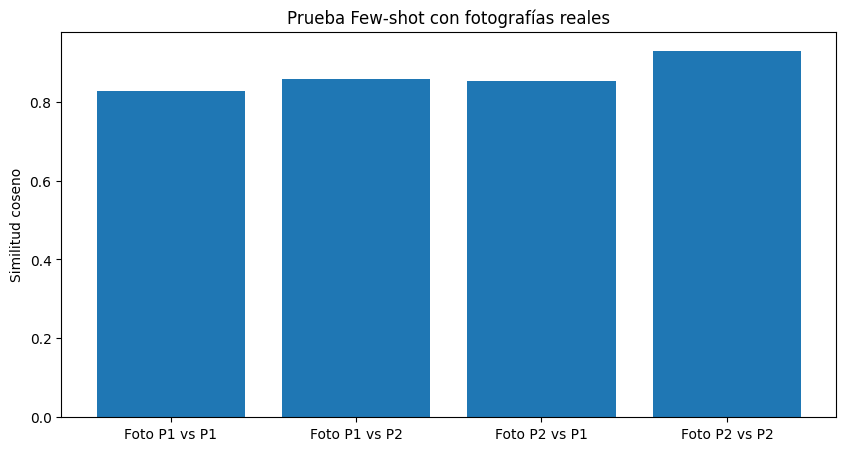

In [ ]:
valores = [
    sim_p1_p1,
    sim_p1_p2,
    sim_p2_p1,
    sim_p2_p2
]

nombres_grafica = [
    'Foto P1 vs P1',
    'Foto P1 vs P2',
    'Foto P2 vs P1',
    'Foto P2 vs P2'
]

plt.figure(figsize=(10, 5))
plt.bar(nombres_grafica, valores)
plt.ylabel('Similitud coseno')
plt.title('Prueba Few-shot con fotografías reales')
plt.show()


### Paso 28. Construir una matriz de similitud de las seis fotografías

Calculamos la matriz de correlación completa realizando el producto matricial entre todos los embeddings extraídos de las 6 imágenes reales. Graficamos este resultado en forma de mapa de calor con una barra de color indicativa para inspeccionar de manera global la similitud mutua entre todas las fotos del experimento.

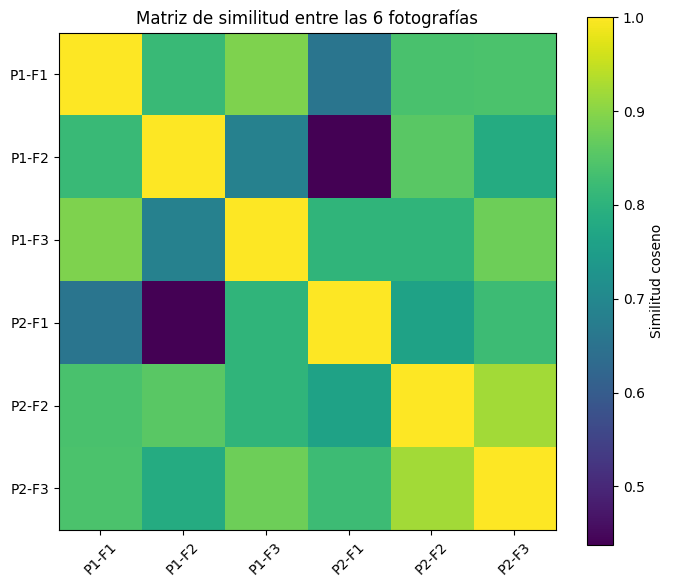

In [ ]:
matriz = embeddings @ embeddings.T
matriz_np = matriz.detach().cpu().numpy()

plt.figure(figsize=(7, 6))
plt.imshow(matriz_np)
plt.colorbar(label='Similitud coseno')

etiquetas = [
    'P1-F1', 'P1-F2', 'P1-F3',
    'P2-F1', 'P2-F2', 'P2-F3'
]

plt.xticks(range(6), etiquetas, rotation=45)
plt.yticks(range(6), etiquetas)
plt.title('Matriz de similitud entre las 6 fotografías')
plt.tight_layout()
plt.show()
